# Topic 22b - Univariate exploration

The main lesson looked at one column, pm2_5. This notebook practices the same move - describe, then visualize - across every numeric column in the air-quality table, plus value_counts for a categorical one, and reading skew correctly.

Work through it after reading section 3 of the [main lesson](topic22_exploratory_data_analysis.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "exploratory_data_analysis" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "air_quality_readings.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find air_quality_readings.csv. Looked in: " +
        ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette (Topic 21) - fixed hue order, never cycled, so a category
# keeps the same colour in every chart it appears in.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"
STATION_TYPE_COLOR = {
    "Roadside": PALETTE["red"], "Industrial": PALETTE["orange"],
    "Residential": PALETTE["aqua"], "Background": PALETTE["blue"],
}
STATION_TYPE_ORDER = ["Roadside", "Industrial", "Residential", "Background"]

WHO_ANNUAL_GUIDELINE = 5.0   # ug/m3, PM2.5 annual mean
WHO_24H_GUIDELINE = 15.0     # ug/m3, PM2.5 24-hour mean

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/exploratory_data_analysis/data
files:             ['air_quality_readings.csv', 'air_quality_readings_assignment.csv', 'air_quality_stations.csv', 'air_quality_stations_assignment.csv', 'customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
stations = pd.read_csv(DATA_DIR / "air_quality_stations.csv")
readings = pd.read_csv(DATA_DIR / "air_quality_readings.csv", parse_dates=["date"])

aq = readings.merge(stations, on="station_id", how="left", validate="m:1")
aq["month"] = aq["date"].dt.month
aq["is_weekend"] = aq["date"].dt.dayofweek.isin([5, 6])
aq["is_harmattan"] = aq["month"].isin([12, 1, 2])

print(f"Air-quality table: {aq.shape[0]} rows x {aq.shape[1]} columns")
print(f"Stations: {aq['station_id'].nunique()}, dates: {aq['date'].min().date()} to {aq['date'].max().date()}")
print(f"Missing pm2_5 readings: {aq['pm2_5'].isna().sum()}")

Air-quality table: 3285 rows x 14 columns
Stations: 9, dates: 2023-01-01 to 2023-12-31
Missing pm2_5 readings: 7


---

## describe() first, always

Before any chart, `.describe()` tells you the five-number summary and the count - which matters, because a column with missing values will silently describe fewer rows than you expect.

In [3]:
for col in ["pm2_5", "pm10", "no2", "temperature_c", "humidity_pct", "wind_speed_kmh"]:
    print(f"--- {col} ---")
    print(aq[col].describe().round(1).to_string())
    print()

--- pm2_5 ---
count    3278.0
mean       44.7
std        22.0
min         6.6
25%        28.9
50%        41.3
75%        57.4
max       261.3

--- pm10 ---
count    3278.0
mean       80.3
std        39.1
min        11.8
25%        52.1
50%        74.2
75%       102.4
max       420.3

--- no2 ---
count    3278.0
mean       24.5
std        10.3
min         5.0
25%        16.6
50%        23.9
75%        32.8
max        49.5

--- temperature_c ---
count    3285.0
mean       27.5
std         2.4
min        19.9
25%        25.5
50%        27.5
75%        29.5
max        33.7

--- humidity_pct ---


count    3285.0
mean       68.3
std        11.4
min        39.8
25%        58.8
50%        69.5
75%        78.2
max        97.1

--- wind_speed_kmh ---
count    3285.0
mean        9.6
std         3.4
min         3.0
25%         7.2
50%         9.0
75%        11.3
max        28.0



Every pollutant column shows 3,278 non-null values against 3,285 rows - the seven missing readings from the sensor outages mentioned in the main lesson. The weather columns are complete, because they come from a separate source that was not affected.

---

## Skew tells you whether the mean is trustworthy

A skew near 0 means the mean and median are close, and the mean is a fair "typical value." A skew well above 1 (or below -1) means a handful of extreme values are pulling the mean away from where most of the data actually sits - exactly what happened with `pm2_5` in the main lesson.

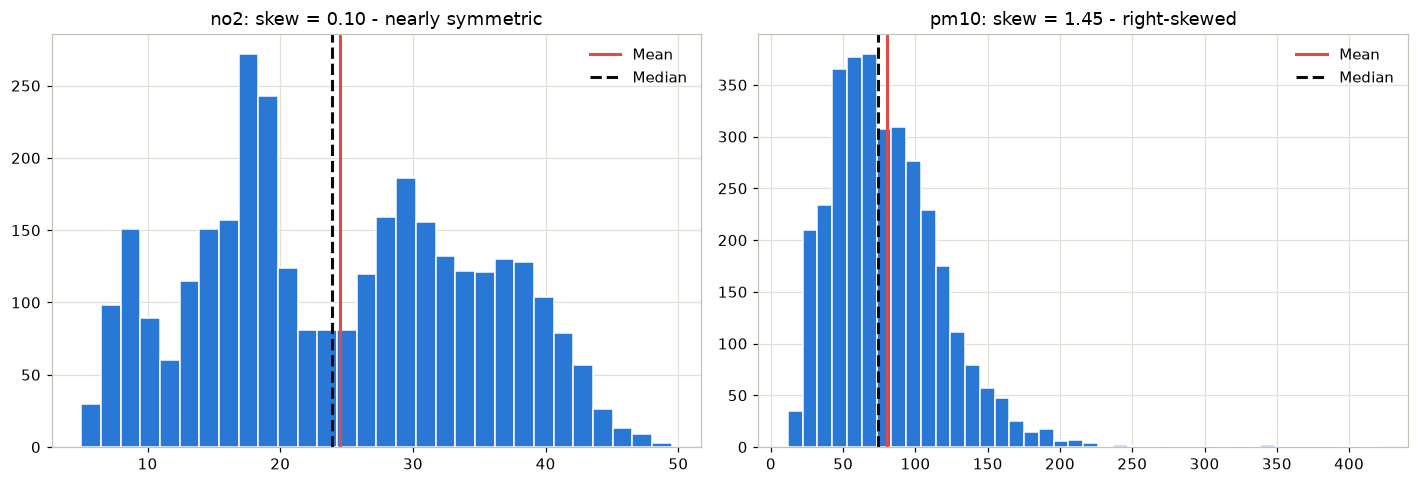

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(aq["no2"].dropna(), bins=30, color=PALETTE["blue"], edgecolor="white")
axes[0].axvline(aq["no2"].mean(), color=PALETTE["red"], linewidth=2, label="Mean")
axes[0].axvline(aq["no2"].median(), color=INK, linestyle="--", linewidth=2, label="Median")
axes[0].set_title(f"no2: skew = {aq['no2'].skew():.2f} - nearly symmetric")
axes[0].legend(frameon=False)

axes[1].hist(aq["pm10"].dropna(), bins=40, color=PALETTE["blue"], edgecolor="white")
axes[1].axvline(aq["pm10"].mean(), color=PALETTE["red"], linewidth=2, label="Mean")
axes[1].axvline(aq["pm10"].median(), color=INK, linestyle="--", linewidth=2, label="Median")
axes[1].set_title(f"pm10: skew = {aq['pm10'].skew():.2f} - right-skewed")
axes[1].legend(frameon=False)

fig.tight_layout()
plt.show()

`no2`'s mean and median sit almost on top of each other in the chart; `pm10`'s do not. Reporting "mean PM10" alone, without the shape behind it, would understate how extreme the worst days really get.

### Try It 3 - describe a shape in words

Pick `temperature_c` or `humidity_pct`, compute its skew, and write one sentence describing its shape (symmetric, right-skewed, or left-skewed) and whether its mean is a trustworthy "typical value."

In [5]:
# YOUR CODE HERE

---

## A categorical column: value_counts, not describe

`.describe()` is for numbers. For a categorical column, `.value_counts()` is the univariate view - and the *count* itself can be a finding, before you even look at any pollutant value.

In [6]:
print(aq["station_type"].value_counts().to_string())
print()
print("Residential and Roadside each have three stations (1,095 station-days); Industrial has")
print("two (730); Background has one (365). Any comparison across station types is therefore")
print("comparing unequal amounts of data - worth remembering before ranking them with confidence.")

station_type
Roadside       1095
Residential    1095
Industrial      730
Background      365

Residential and Roadside each have three stations (1,095 station-days); Industrial has
two (730); Background has one (365). Any comparison across station types is therefore
comparing unequal amounts of data - worth remembering before ranking them with confidence.


### Try It 4 - your own univariate pass

Choose any column in `aq` not yet explored in this notebook, run `.describe()` or `.value_counts()` as appropriate, build one chart, and write one sentence stating what is typical and what, if anything, is unusual.

In [7]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic22_exploratory_data_analysis.ipynb)
- Previous: [22a - Asking good questions](topic22a_asking_good_questions.ipynb)
- Next: [22c - Bivariate exploration](topic22c_bivariate_exploration.ipynb)